# 9.3 - Model: SVM (Support Vector Machine) (Lancaster stemmed variant)

**Training and evaluation of the Support Vector Machine classifier on the Lancaster stemmed variant of the TF-IDF data.**

## Theoretical Foundation

Represents reviews as points in a plane - some labeled as "positive", some as "negative" - we try to draw a line that separates them.
The problem is that there are usually many lines that could do this correctly, not just one.

Support Vector Machine (SVM) looks for a hyperplane (decision boundary) that separates the two classes with the maximum margin - the greatest possible distance to the closest points of both classes (it chooses exactly the line that is furthest from the closest points of both classes).

These closest points are called "support vectors" - the only points that directly determine the boundary.

All others can be moved without affecting the result, as long as they do not cross the margin.

The model is trained by minimizing the hinge loss function: `max(0, 1 - y·f(x))`
- the penalty is 0 if the example is correctly classified WITH a sufficient margin
- it increases linearly as the example gets closer to the boundary from either side (the further it is on the wrong side of the boundary - the greater the penalty).

This is different from Logistic Regression (`5.x`), which minimizes log-loss and always "pushes" toward a more certain prediction, even for examples that are already far away and clearly correctly classified - SVM stops "caring" about the example as soon as it is classified well enough (the penalty becomes exactly 0).

## Why the Widest Margin

If the boundary is "squeezed" right next to the points (narrow margin), a new, unseen review that falls close to the boundary can easily end up on the wrong side — a small difference is enough to change the prediction.

A wide margin provides "room to breathe" — a new review has to be significantly different to be misclassified.

## Why `LinearSVC` instead of `SVC` with a Kernel

- Standard `SVC` with a kernel
    - A nonlinear kernel allows the model to form more complex, nonlinear decision boundaries
    - However, the kernel approach requires calculating relationships between a large number of examples, which means its memory and time complexity quickly grows with the number of examples
    - It has a time complexity of approximately O(n²)-O(n³) with respect to the number of training examples
    - With a dataset of 39.665 training reviews. The number of possible pairs of reviews is approximately 39.665² ≈ 1.57 billion examples - almost infeasibly slow with the available resources

- `LinearSVC`
    - Uses a different, much more efficient algorithm designed specifically for the linear case
    - Uses a linear decision boundary and is optimized specifically for large, high-dimensional text datasets
    - Since our data has 68.378 features (high-dimensional space), a linear boundary is often expressive enough
    - When there are so many dimensions available, a linear model already has enormous flexibility to separate the classes, without the need for a nonlinear kernel

## `hinge` and `squared_hinge` loss

- `squared_hinge`
    - Formula: `(max(0, 1 - y·f(x)))²`
    - For an example where the `"hinge"` penalty would be X, the squared version would be X² — a much sharper penalty for large errors, the penalty grows quadratically instead of linearly
    - `LinearSVC` uses `squared_hinge` (squared version, smoother for optimization) by default

- `"hinge"`
    - Formula: `max(0, 1 - y·f(x))`
    - The penalty grows linearly, proportionally to how far it is from its correct side
    - We explicitly also select `loss="hinge"` - the "true", classic SVM formulation from theory (linear, not quadratic penalty), for fidelity to the standard definition of the model

## Why We Do Not Search L1 vs L2 (as in `5.x`)

- In `5.x` we empirically showed that L2 convincingly outperforms L1 on this data
- The signal is distributed across thousands of moderately-scored terms (confirmed by statistical analysis in `3_vectorization.ipynb`)
- It is not concentrated in a small number of strong terms that L1 selection would favor
- The same logic directly applies to SVM - therefore we fix `l2` (default) instead of repeating the identical experiment

## Processing Pipeline:

1. We load the previously prepared Lancaster stemmed TF-IDF data using the `load_variant()` function

2. We create a `LinearSVC` classifier and define the values of the `C` and `loss` hyperparameters that `GridSearchCV` will test

3. We call the shared `train_and_evaluate()` function:
    1. GridSearchCV on the TRAIN set:
        - tests all combinations of hyperparameters from param_grid
        - uses k-fold cross-validation (5 folds by default)
        - selects the combination of hyperparameters that gives the best F1 score
    2. Final model:
        - after selecting the best hyperparameters, GridSearchCV trains the best model on the entire TRAIN set
    3. Evaluation:
        - the best model is used on the TEST set for the first time
        - accuracy, precision, recall, and F1 are calculated, and a confusion matrix is created
    4. Saving the results

4. We analyze the terms with the highest positive and negative coefficients.


In [1]:
import sys
sys.path.append("..")

import numpy as np
import joblib

from src.data_io import load_variant
from src.modeling import train_and_evaluate

from sklearn.svm import LinearSVC

## Data Loading

We load the stemmed variant (TF-IDF matrices + labels), saved in `3_vectorization.ipynb`.


In [2]:
X_train, X_test, y_train, y_test = load_variant("lancaster")

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

Train: (39665, 68378)
Test:  (9917, 68378)


## Model and Hyperparameters

Hyperparameters: `C` and `loss`

- `C` - inversely proportional to the strength of regularization, with the same meaning as in Logistic Regression (`5.x`)
  - Smaller `C` → stronger regularization, wider margin, more tolerance for margin violations
  - Larger `C` → weaker regularization, narrower margin, less tolerance for violations

- `loss` - the loss function that SVM uses during optimization
  - `hinge` → classic hinge loss function
  - `squared_hinge` → squared version of the hinge loss function

`dual=True`:

- The same mathematical problem (finding the best boundary) that can be solved in two equivalent ways:
  - "primal" - optimization is performed directly over the feature weights — 68.378 unknowns
  - "dual" (dual) - works with one unknown per training example — 39.665 unknowns

- Which one is faster depends on whether you have more features or more examples:
  - More features than examples (our case: 68.378 > 39.665) → dual is faster
  - More examples than features → primal is faster

- Since we have more features than examples, `dual=True` is the more efficient choice for us

`max_iter`:

- We increase `max_iter` from the default 1,000 to 10,000 to allow the optimization algorithm a sufficient number of iterations for convergence
- Represents the maximum number of iterations (not the number of iterations the model will necessarily perform)
- If the model converges earlier, training finishes before reaching this limit


In [3]:
model = LinearSVC(penalty="l2", dual=True, max_iter=10000, random_state=1)

param_grid = {
    "C": [0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1, 5, 10],
    "loss": ["hinge", "squared_hinge"],
}

## Training and Evaluation

Calls `train_and_evaluate()` from `src/modeling.py`.

The function tests all specified combinations of `C` and `loss` values using 5-fold GridSearchCV on the training set, selects the combination with the best F1 score, then trains the best model on the entire training set and evaluates it on the test set.

The results are saved as the model, metrics, and confusion matrix.


========== svm (lanc) ==========
Best parameters: {'C': 0.7, 'loss': 'squared_hinge'}
GridSearchCV time: 91.0s

Accuracy  : 0.9086
Precision : 0.9030
Recall    : 0.9164
F1        : 0.9097


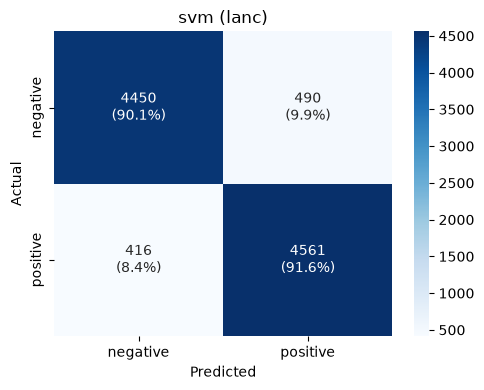


Saved:
  ..\models\svm_lanc.joblib
  ..\results\metrics\svm_lanc.json
  ..\results\figures\svm_lanc_confusion_matrix.png


In [4]:
metrics = train_and_evaluate(
    model=model,
    param_grid=param_grid,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="svm",
    variant="lanc",
)

## Most Influential Terms (Coefficient Interpretation)

The same approach as in `5.x` - `LinearSVC` is also a linear model, so `coef_` directly shows how much the presence of a term pushes the prediction toward positive (positive coefficient) or negative (negative coefficient) sentiment.


In [5]:
best_model = joblib.load("../models/svm_lanc.joblib")
vectorizer = joblib.load("../models/tfidf_vectorizer_lanc.joblib")

feature_names = np.array(vectorizer.get_feature_names_out())
coefficients = best_model.coef_[0]

top_positive_idx = np.argsort(coefficients)[-20:][::-1]
top_negative_idx = np.argsort(coefficients)[:20]

print("Top 20 terms most strongly associated with POSITIVE sentiment:")
for idx in top_positive_idx:
    print(f"  {feature_names[idx]:30s}  {coefficients[idx]:+.3f}")

print("\nTop 20 terms most strongly associated with NEGATIVE sentiment:")
for idx in top_negative_idx:
    print(f"  {feature_names[idx]:30s}  {coefficients[idx]:+.3f}")

Top 20 terms most strongly associated with POSITIVE sentiment:
  excel                           +3.646
  not disappoint                  +3.420
  gre                             +3.222
  perfect                         +2.977
  bril                            +2.794
  high recommend                  +2.694
  must see                        +2.458
  favorit                         +2.437
  enjoy                           +2.422
  fun                             +2.350
  today                           +2.312
  surpr                           +2.285
  wel wor                         +2.277
  refresh                         +2.261
  amaz                            +2.198
  superb                          +2.174
  on best                         +2.148
  best                            +2.148
  definit wor                     +2.026
  entertain                       +2.003

Top 20 terms most strongly associated with NEGATIVE sentiment:
  worst                           -4.625
  wast      

## Conclusions

- Best `C`: 0.7, `loss`: squared_hinge

- Results:
  - Accuracy  : 0.9086
  - Precision : 0.9030
  - Recall    : 0.9164
  - F1        : 0.9097

- The most influential terms match expectations:
  - positive: excel, great, perfect, not disappoint, enjoy, love,...
  - negative: worst, awfull, poor, bad, disappoint, boring, waste,...

- SVM, like Logistic Regression, performs well in the same TF-IDF space with similar performance because both are linear models, although they use different loss functions.

- Comparing the most influential terms between SVM and Logistic Regression shows a large number of terms appearing on both lists, indicating that both models identify the same terms as the most important for determining sentiment

- The results confirm that linear SVM is highly suitable for classifying text data represented using TF-IDF, especially when the number of features is large
